In [58]:
#Importo bibliotecas a utilizar
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from IPython.display import display, HTML
import missingno as msno
from scipy.stats import f_oneway
import math


# Exploración inicial del dataset


In [14]:
#Cargo el dataset
dataset_path = "../datasets/Data_Cortex_Nuclear.xls"
data = pd.read_excel(dataset_path, engine="calamine")



# ============================================================
# INFORMACIÓN GENERAL
# ============================================================

print("=" * 60)
print("EXPLORACIÓN INICIAL DEL DATASET")
print("=" * 60)

#Variables
num_cols = data.select_dtypes(include="number").columns.tolist()
meta_cols = data.columns.difference(num_cols, sort=False).tolist()

#Identificación de ratones sin número de repetición
mouse_ids = data["MouseID"].str.rsplit("_", n=1).str[0]

print(f"\nDimensiones:         {data.shape}")
print(f"Total observaciones: {len(data)}")
print(f"Ratones únicos:      {mouse_ids.nunique()}")
print(f"Mediciones únicas:   {data['MouseID'].nunique()}")
print(f"Variables proteicas: {len(num_cols)}")
print(f"Metadatos:           {len(meta_cols)}")


# ============================================================
# VARIABLES Y TIPOS DE DATOS
# ============================================================

print("\n" + "=" * 60)
print("VARIABLES Y TIPOS DE DATOS")
print("=" * 60)

print("\nMetadatos:")
display(data[meta_cols].dtypes.to_frame("Tipo"))

print("\nProteínas:")
display(data[num_cols].dtypes.value_counts().to_frame("Cantidad"))


# ============================================================
# EXPLORACIÓN DE METADATOS
# ============================================================

print("\n" + "=" * 60)
print("EXPLORACIÓN DE METADATOS")
print("=" * 60)

display(data[meta_cols].describe(include="all").T)

# Distribución de categorías
for col in ["Genotype", "Treatment", "Behavior", "class"]:
    print(f"\nDistribución de {col}:")
    display(data[col].value_counts(dropna=False).to_frame("Frecuencia"))


# ============================================================
# ESTADÍSTICAS DESCRIPTIVAS DE PROTEÍNAS
# ============================================================

print("\n" + "=" * 60)
print("ESTADÍSTICAS DESCRIPTIVAS DE PROTEÍNAS")
print("=" * 60)

protein_stats = data[num_cols].describe().T.round(3)

display(protein_stats)

EXPLORACIÓN INICIAL DEL DATASET

Dimensiones:         (1080, 82)
Total observaciones: 1080
Ratones únicos:      72
Mediciones únicas:   1080
Variables proteicas: 77
Metadatos:           5

VARIABLES Y TIPOS DE DATOS

Metadatos:


,Tipo
MouseID,str
Genotype,str
Treatment,str
Behavior,str
class,str



Proteínas:


,Cantidad
float64,77



EXPLORACIÓN DE METADATOS


,count,unique,top,freq
MouseID,1080,1080,309_1,1
Genotype,1080,2,Control,570
Treatment,1080,2,Memantine,570
Behavior,1080,2,S/C,555
class,1080,8,c-CS-m,150


... (6 outputs left out)


Distribución de class:


,Frecuencia
class,
c-CS-m,150
c-SC-m,150
c-CS-s,135
c-SC-s,135
t-CS-m,135
t-SC-m,135
t-SC-s,135
t-CS-s,105



ESTADÍSTICAS DESCRIPTIVAS DE PROTEÍNAS


,count,mean,std,min,25%,50%,75%,max
DYRK1A_N,1077.0,0.426,0.249,0.145,0.288,0.366,0.488,2.516
ITSN1_N,1077.0,0.617,0.252,0.245,0.473,0.566,0.698,2.603
BDNF_N,1077.0,0.319,0.049,0.115,0.287,0.317,0.348,0.497
NR1_N,1077.0,2.297,0.347,1.331,2.057,2.297,2.528,3.758
NR2A_N,1077.0,3.844,0.933,1.738,3.156,3.761,4.440,8.483
...,...,...,...,...,...,...,...,...
SYP_N,1080.0,0.446,0.066,0.259,0.398,0.448,0.491,0.760
H3AcK18_N,900.0,0.170,0.059,0.080,0.126,0.158,0.198,0.480
EGR1_N,870.0,0.183,0.040,0.106,0.155,0.175,0.205,0.361
H3MeK4_N,810.0,0.205,0.056,0.102,0.165,0.194,0.235,0.414


# Tipos de Variables del dataset

En lo analizado numéricamente se observa que el dataset tiene **1080 muestras** y **82 variables**.

Se dividen en dos grupos:

- **5 variables categóricas** (`str`): `MouseID`, `Genotype`, `Treatment`, `Behavior` y `class`. Son identificadores y factores experimentales (genotipo, fármaco, condición de comportamiento y clase objetivo).

- **77 variables numéricas** (`float64`): todas terminan en `_N` y representan niveles de expresión proteica normalizados en el núcleo cerebral. Incluyen proteínas fosforiladas (prefijo `p`, ej: `pAKT_N`, `pERK_N`), receptores, factores de transcripción y marcadores de señalización celular.

MouseID es el identificador y está compuesto por ID_REPETICION donde existen 15 repeticiones para cada ratón.


In [39]:
#Funciones para graficar distribuciones de variables numéricas y boxplots

sns.set_theme(
    style="whitegrid",
    context="notebook",
    font_scale=1.05,
    rc={
        "figure.facecolor": "white",
        "axes.facecolor": "#FAFBFC",
        "axes.edgecolor": "#D0D7DE",
        "grid.color": "#E5E9ED",
        "grid.alpha": 0.6,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

# Colores
COLOR_DATA = "#619EBA"
COLOR_MEAN = "#D97757"
COLOR_MEDIAN = "#328C80"
COLOR_DARK = "#264653"

def plot_protein_distributions(data, num_cols, start=0, n=6, ncols=3):

    selected = num_cols[start:start+n]

    if not selected:
        return

    nrows = math.ceil(len(selected) / ncols)

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(5 * ncols, 3.8 * nrows),
        constrained_layout=True,
        squeeze=False
    )

    axes = axes.flatten()

    for ax, col in zip(axes, selected):

        values = data[col].dropna()

        if values.empty:
            ax.set_title(f"{col} (sin datos)")
            continue

        mean = values.mean()
        median = values.median()

        # Histograma + KDE
        sns.histplot(
            values,
            bins="auto",
            kde=True,
            color=COLOR_DATA,
            alpha=0.65,
            edgecolor="white",
            linewidth=0.6,
            line_kws={"linewidth": 2},
            ax=ax
        )

        # Media
        ax.axvline(
            mean,
            color=COLOR_MEAN,
            linestyle="--",
            linewidth=2,
            label=f"Media: {mean:.3f}"
        )

        # Mediana
        ax.axvline(
            median,
            color=COLOR_MEDIAN,
            linestyle="-",
            linewidth=2,
            label=f"Mediana: {median:.3f}"
        )

        ax.set_title(
            col,
            fontsize=12,
            fontweight="bold",
            color=COLOR_DARK,
            pad=12
        )

        ax.set_xlabel("Expresión proteica", fontsize=10)
        ax.set_ylabel("Frecuencia", fontsize=10)

        ax.legend(
            loc="upper right",
            fontsize=9,
            frameon=True,
            facecolor="white",
            edgecolor="#E5E9ED"
        )

        ax.grid(axis="y", alpha=0.3)
        ax.grid(axis="x", visible=False)

        sns.despine(ax=ax)

    # Ocultar ejes vacíos
    for ax in axes[len(selected):]:
        ax.set_visible(False)

    fig.suptitle(
        "Distribución de expresión proteica",
        fontsize=17,
        fontweight="bold",
        color=COLOR_DARK
    )

    plt.show()

def plot_protein_boxplots(data, num_cols, start=0, n=6, ncols=3):

    selected = num_cols[start:start+n]

    if not selected:
        return

    nrows = math.ceil(len(selected) / ncols)

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(5 * ncols, 3.8 * nrows),
        constrained_layout=True,
        squeeze=False
    )

    axes = axes.flatten()

    for ax, col in zip(axes, selected):

        values = data[col].dropna()

        if values.empty:
            ax.set_title(f"{col} (sin datos)")
            continue

        sns.boxplot(
            y=values,
            ax=ax,
            color=COLOR_DATA,
            width=0.35,
            linewidth=1.4,

            # Media
            showmeans=True,
            meanprops={
                "marker": "D",
                "markerfacecolor": COLOR_MEAN,
                "markeredgecolor": "white",
                "markersize": 8
            },

            # Mediana
            medianprops={
                "color": COLOR_DARK,
                "linewidth": 2.5
            },

            # Bigotes
            whiskerprops={
                "color": COLOR_DARK,
                "linewidth": 1.4
            },

            capprops={
                "color": COLOR_DARK,
                "linewidth": 1.4
            },

            # Valores atípicos
            flierprops={
                "marker": "o",
                "markerfacecolor": COLOR_DATA,
                "markeredgecolor": COLOR_DARK,
                "markersize": 3.5,
                "alpha": 0.5
            }
        )

        ax.set_title(
            col,
            fontsize=12,
            fontweight="bold",
            color=COLOR_DARK,
            pad=12
        )

        ax.set_ylabel("Expresión proteica", fontsize=10)
        ax.set_xlabel("")

        ax.set_xticks([])

        ax.grid(axis="y", alpha=0.3)
        ax.grid(axis="x", visible=False)

        sns.despine(ax=ax, bottom=True)

    # Ocultar ejes vacíos
    for ax in axes[len(selected):]:
        ax.set_visible(False)

    fig.suptitle(
        "Variabilidad de expresión proteica",
        fontsize=17,
        fontweight="bold",
        color=COLOR_DARK
    )

    plt.show()

def plot_categorical_distributions(data, cat_cols):

    fig, axes = plt.subplots(
        2, 2,
        figsize=(15, 11),
        constrained_layout=True
    )

    axes = axes.flatten()

    colors = sns.color_palette("Set2", 10)

    for ax, col in zip(axes, cat_cols):

        counts = data[col].value_counts(dropna=False)
        total = counts.sum()

        # Para variables con pocas categorías: gráfico de dona
        if len(counts) <= 4:

            wedges, texts, autotexts = ax.pie(
                counts,
                colors=colors[:len(counts)],
                startangle=90,
                counterclock=False,
                autopct="%1.1f%%",
                pctdistance=0.78,
                wedgeprops={
                    "width": 0.4,
                    "edgecolor": "white",
                    "linewidth": 2
                },
                textprops={
                    "fontsize": 10,
                    "fontweight": "bold"
                }
            )

            # Cantidad de ratones en el centro
            ax.text(
                0, 0,
                f"n = {total}",
                ha="center",
                va="center",
                fontsize=15,
                fontweight="bold",
                color=COLOR_DARK
            )

            ax.legend(
                wedges,
                counts.index.astype(str),
                title="Categorías",
                loc="center left",
                bbox_to_anchor=(1, 0.5),
                frameon=False,
                fontsize=10
            )

            ax.set_aspect("equal")

        # Para variables con muchas categorías: barras horizontales
        else:

            sns.barplot(
                x=counts.values,
                y=counts.index.astype(str),
                hue=counts.index.astype(str),
                palette="Set2",
                legend=False,
                ax=ax
            )

            for i, value in enumerate(counts.values):

                ax.text(
                    value + 0.1,
                    i,
                    f"{value} ({value / total * 100:.1f}%)",
                    va="center",
                    fontsize=9
                )

            ax.set_xlim(0, max(counts.values) * 1.35)

            ax.set_xlabel("Cantidad de ratones")
            ax.set_ylabel("")

            sns.despine(ax=ax, left=True)

        ax.set_title(
            col,
            fontsize=14,
            fontweight="bold",
            color=COLOR_DARK,
            pad=15
        )

    # Ocultar ejes sobrantes
    for ax in axes[len(cat_cols):]:
        ax.set_visible(False)

    fig.suptitle(
        "Distribución de variables categóricas",
        fontsize=19,
        fontweight="bold",
        color=COLOR_DARK
    )

    plt.show()

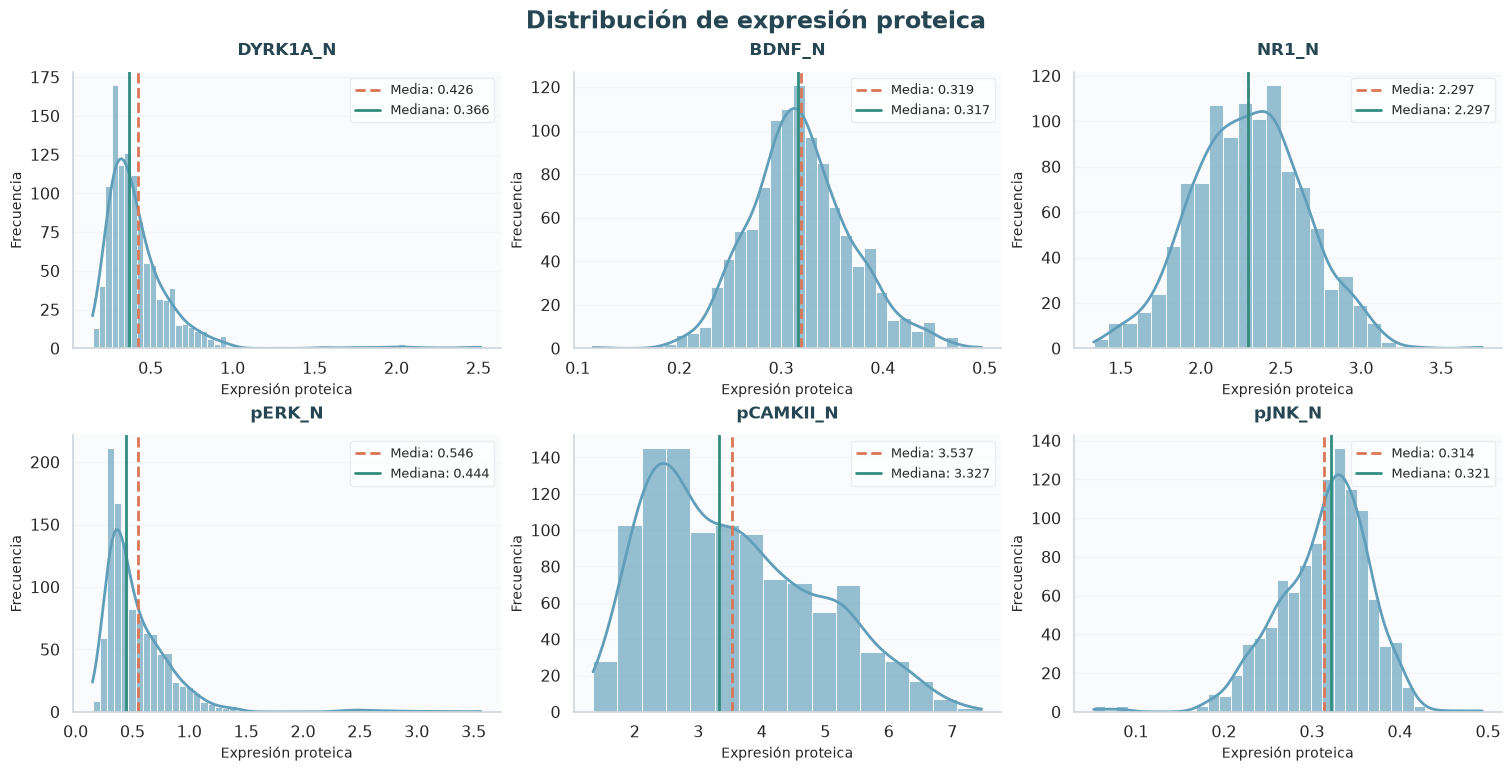

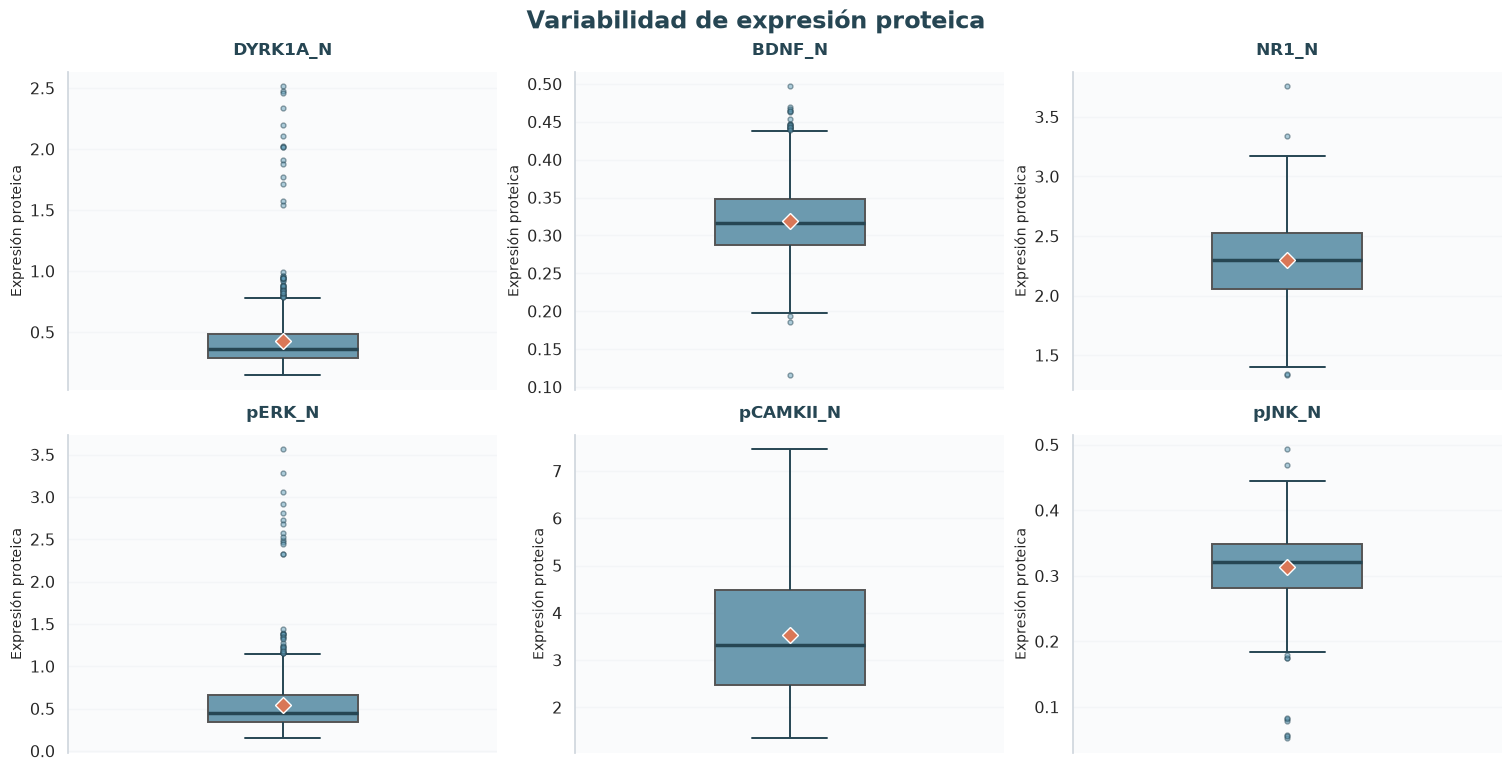

In [40]:
# -----------------------------------------------------------
# Seleccioné 6 variables númericas de expresión de proteínas para mostrar las distribuciones y boxplots. 
# -----------------------------------------------------------

selected_proteins = [
    "DYRK1A_N",
    "BDNF_N",
    "NR1_N",
    "pERK_N",
    "pCAMKII_N",
    "pJNK_N"
]

plot_protein_distributions(
    data,
    selected_proteins,
    n=6
)

plot_protein_boxplots(
    data,
    selected_proteins,
    n=6
)

### Análisis de las distribuciones

En los gráficos anteriores se observa que la mayoría de las proteínas seleccionadas presentan distribuciones asimétricas, con colas hacia la derecha o izquierda y presencia de outliers. Por otro lado, variables como **NR1_N** muestran una distribución visualmente más cercana a la normalidad.

Para análisis posteriores, sería interesante evaluar transformaciones de los datos, como la logarítmica, que podrían reducir la asimetría.

Ratones: 72


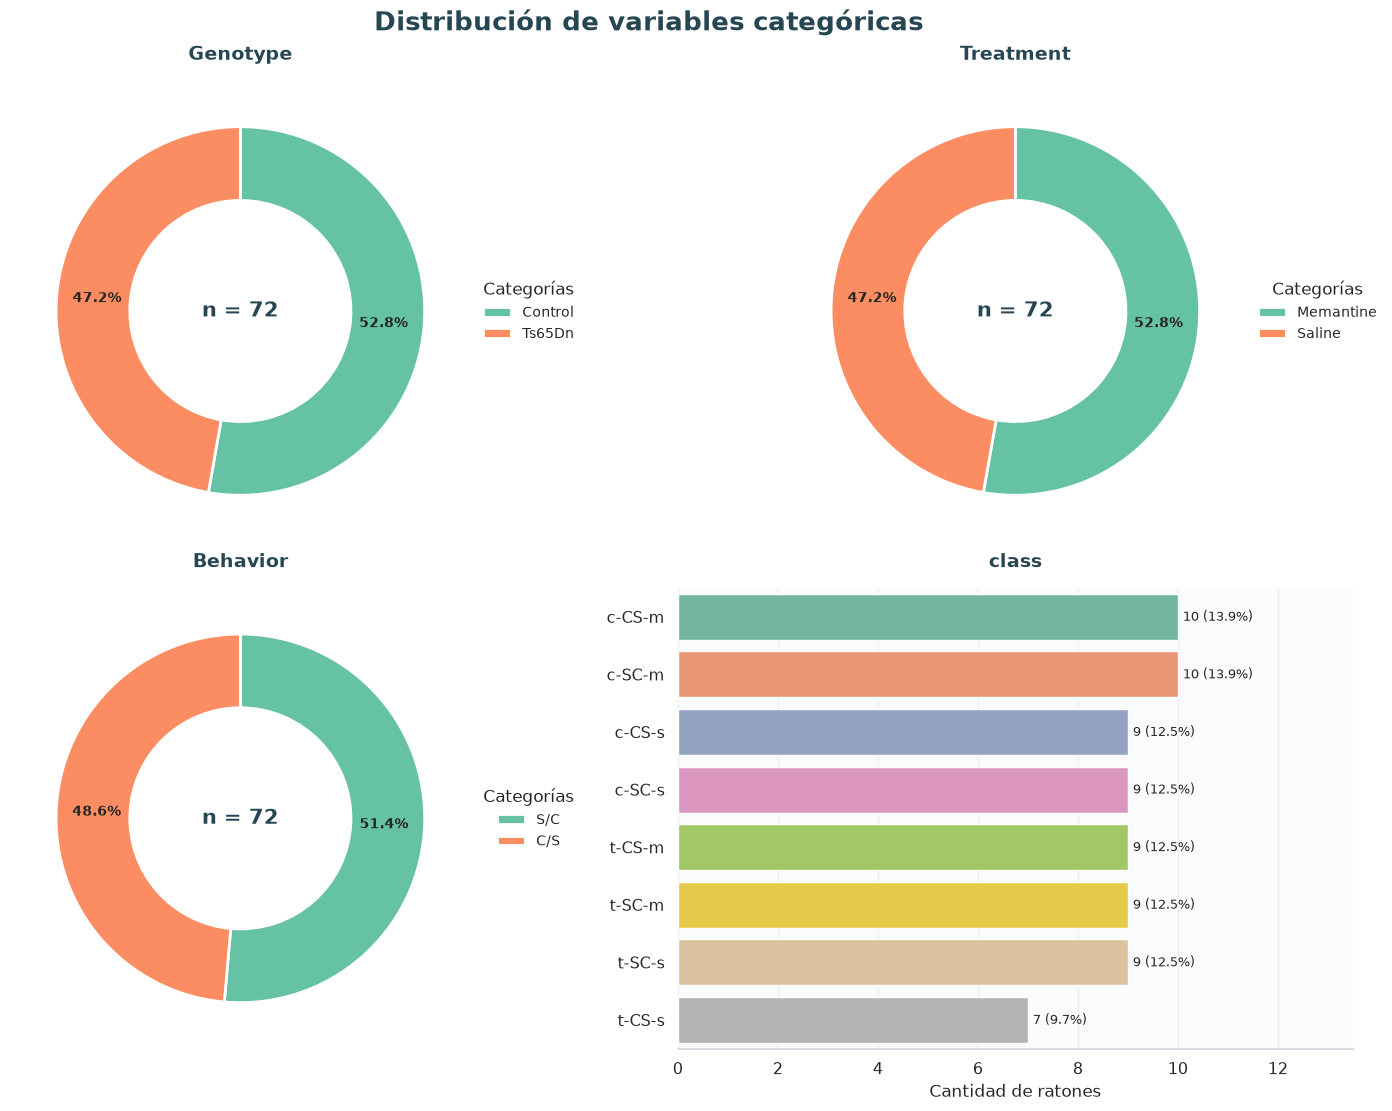

In [ ]:
#Variables categóricas
cat_cols = ["Genotype", "Treatment", "Behavior", "class"]

df_mice = data.copy()

df_mice["Mouse"] = (
    df_mice["MouseID"]
    .str.rsplit("_", n=1)
    .str[0]
)

df_mice = df_mice.drop_duplicates(subset="Mouse")

print(f"Ratones: {len(df_mice)}")

plot_categorical_distributions(df_mice, cat_cols)

# Análisis de datos faltantes


In [ ]:
# ============================================================
# ANÁLISIS DE VALORES FALTANTES
# ============================================================

print("\n" + "=" * 60)
print("ANÁLISIS DE VALORES FALTANTES")
print("=" * 60)

# Resumen de valores faltantes
missing = pd.DataFrame({
    "N_missing": data[num_cols].isna().sum(),
    "Percent_missing": data[num_cols].isna().mean() * 100
})

missing = missing.sort_values("Percent_missing", ascending=False)

# Resumen general
total_missing = data[num_cols].isna().sum().sum()
total_values = data[num_cols].size

print(f"\nTotal valores faltantes:   {total_missing}")
print(f"Porcentaje faltante:      {total_missing / total_values * 100:.2f}%")
print(f"Proteínas afectadas:      {(missing['N_missing'] > 0).sum()}")

print("\nProteínas con valores faltantes:")
display(missing[missing["N_missing"] > 0].round(2))


ANÁLISIS DE VALORES FALTANTES

Total valores faltantes:   1396
Porcentaje faltante:      1.68%
Proteínas afectadas:      49

Proteínas con valores faltantes:


,N_missing,Percent_missing
BCL2_N,285,26.39
H3MeK4_N,270,25.00
BAD_N,213,19.72
EGR1_N,210,19.44
H3AcK18_N,180,16.67
pCFOS_N,75,6.94
ELK_N,18,1.67
Bcatenin_N,18,1.67
MEK_N,7,0.65
ITSN1_N,3,0.28


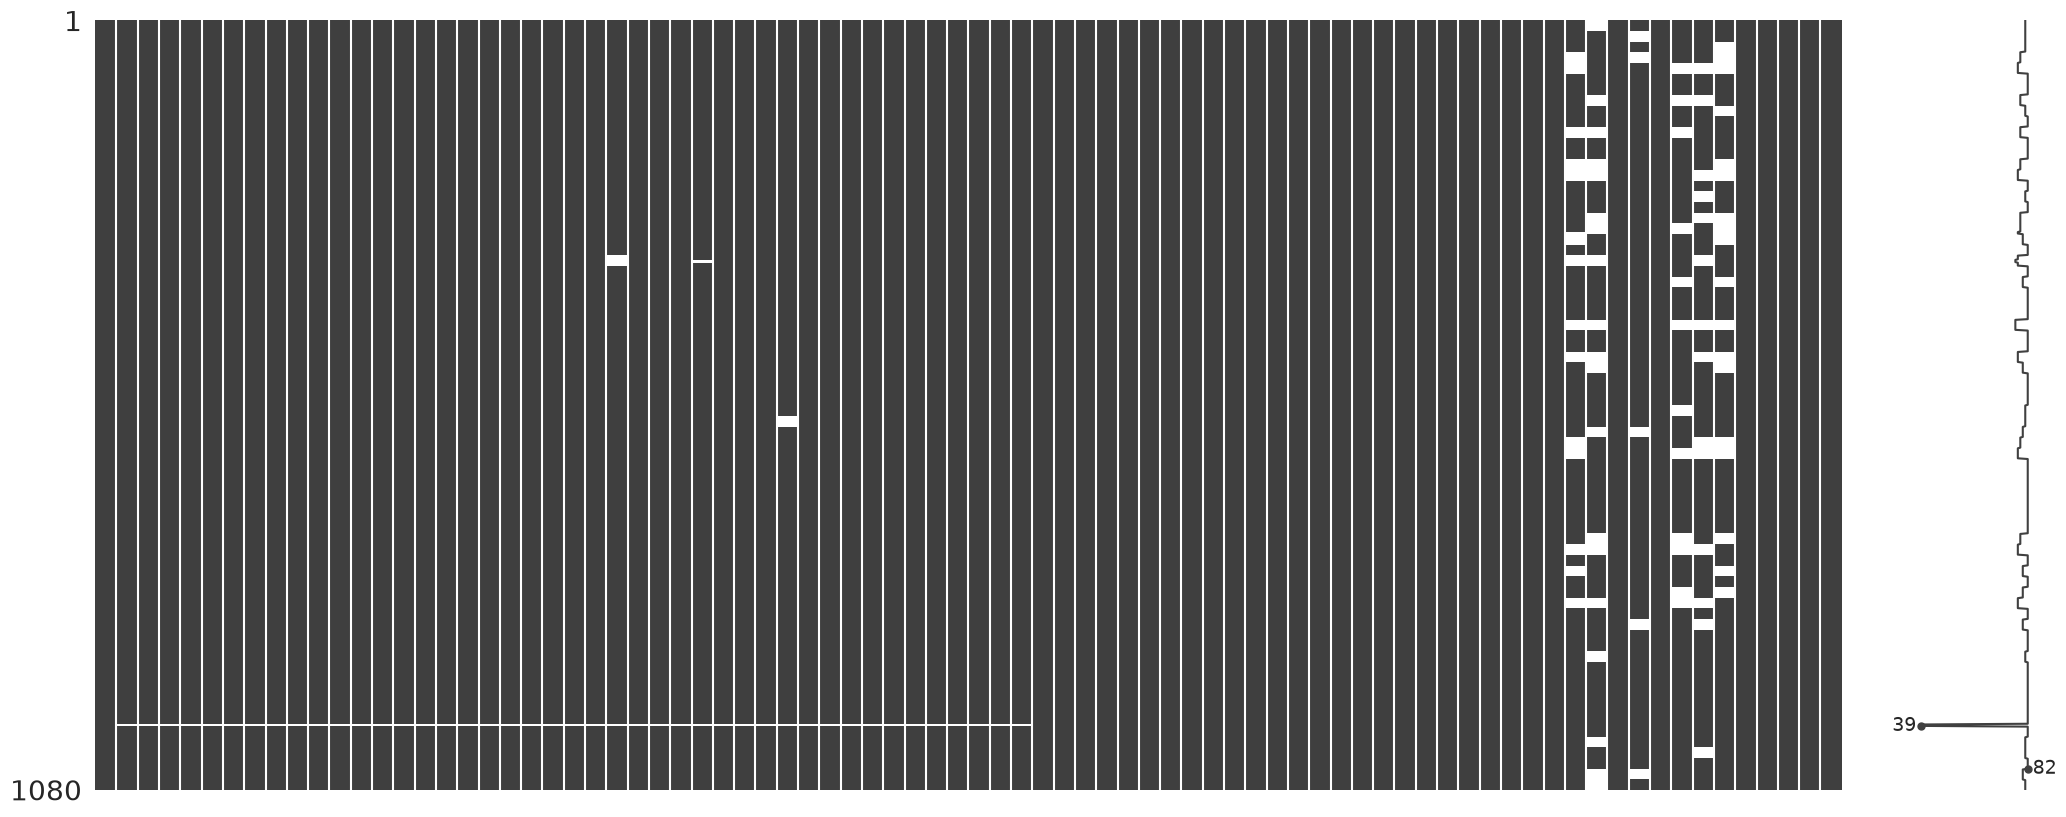

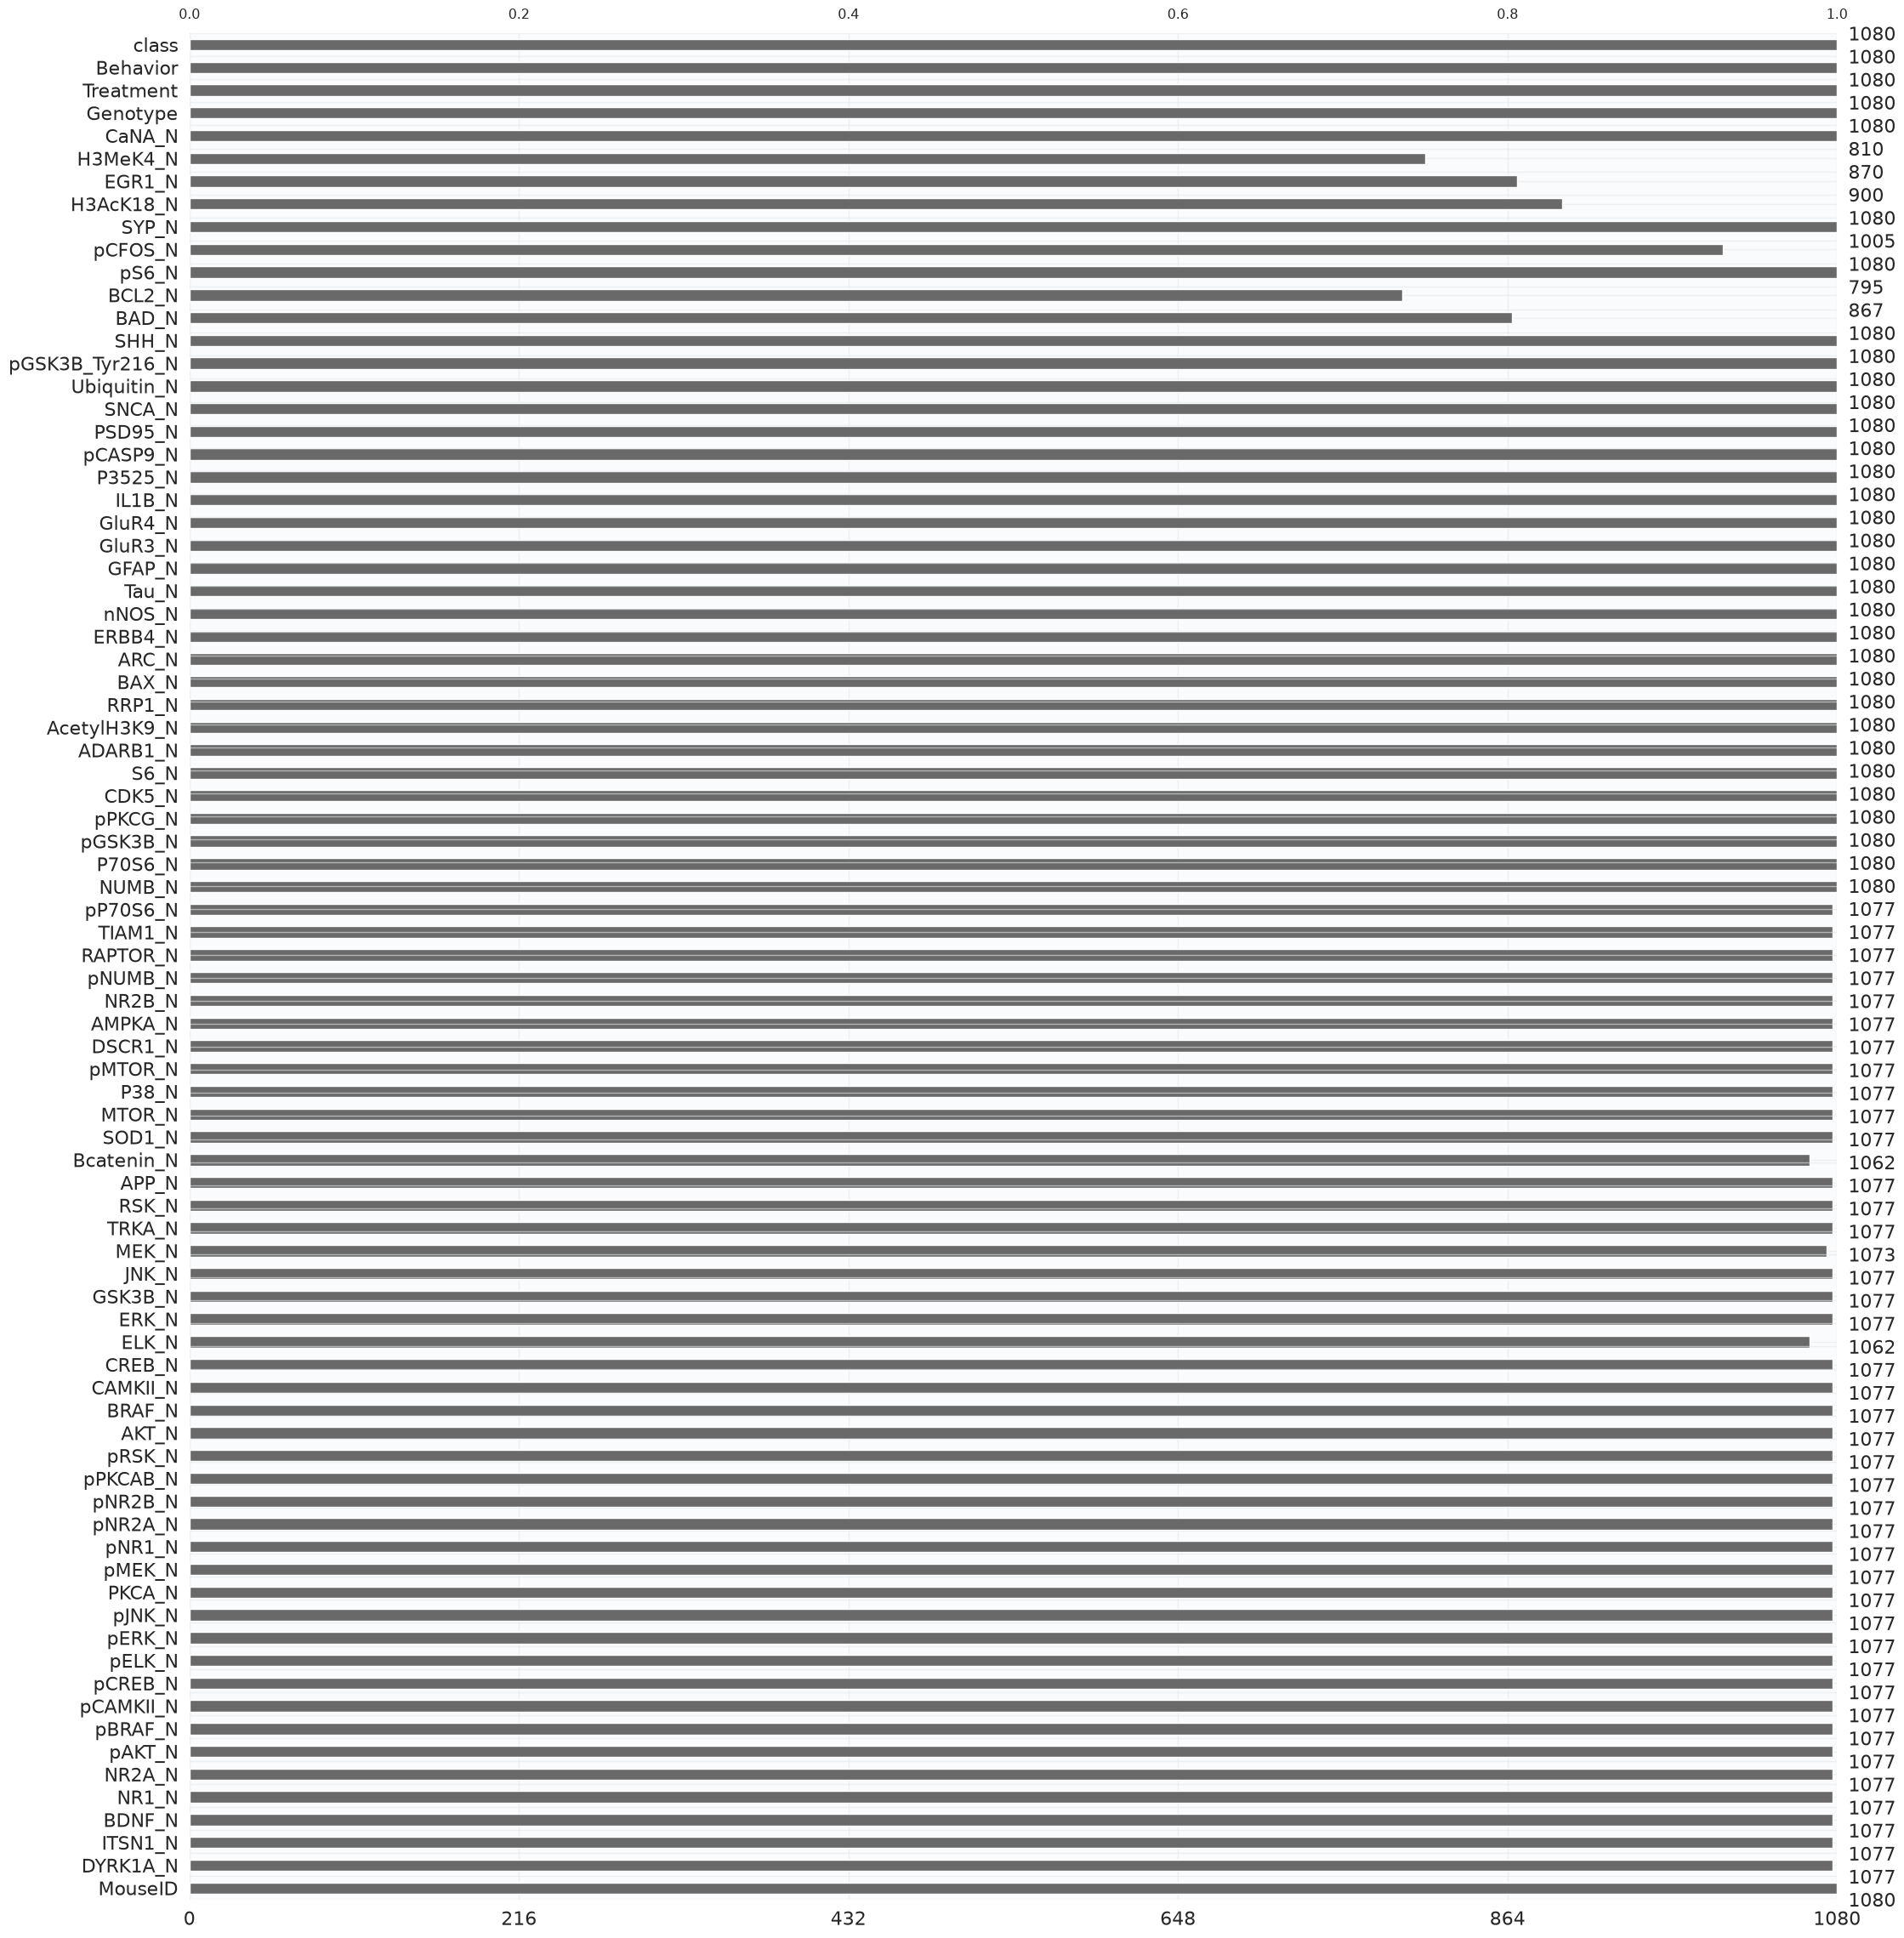

In [49]:
# ============================================================
# VISUALIZACIÓN DE DATOS FALTANTES
# ============================================================
msno.matrix(data)
plt.show()

msno.bar(data)
plt.show()

# A partir de lo visto

Observo que hay datos faltantes de una gran cantidad de mediciones de proteínas en 3 observaciones, estas son 3426_13, 3426_14 y 3426_15 que podrían no tenerse en cuenta en análisis posteriores. Además, se observan datos faltantes que podrían ser inherentes de las proteínas en aproximadamente 5 de ellas distribuidas en las observaciones. 

## ¿Porqué sucede esto de las 3 observaciones consecutivas sin datos? 
Allí me surgió la duda de porqué sucedio esto. Me llamó la atención que los autores sugieren tratar cada medición como independiente lo que me generó dudas. Por cómo están identificadas las muestras mediante `ID_rep`, me parece que podrían ser réplicas de un mismo ratón y, por lo tanto, **no serían observaciones independientes**.

## Planteo

El dataset contiene **72 ratones × 15 mediciones = 1080 observaciones**.

Para evaluar esto, busqué métodos que permitieran comparar la variabilidad entre ratones y dentro de cada ratón. Encontré el **coeficiente de correlación intraclase (ICC)** y decidí complementarlo con un **ANOVA de un factor**, que ya conocía.

---

## 1. Coeficiente de correlación intraclase (ICC)

El ICC permite evaluar qué tan similares son las mediciones de un mismo ratón en comparación con las de ratones diferentes.

$$
ICC = \frac{MS_{entre}-MS_{dentro}}{MS_{entre}+(k-1)MS_{dentro}}
$$

Donde:
- $MS_{entre}$: variabilidad entre ratones.
- $MS_{dentro}$: variabilidad de las réplicas dentro de cada ratón.
- $k$: número de mediciones por ratón (15).

**Hipótesis:**
- **H₀:** todos los ratones tienen el mismo promedio.
- **H₁:** al menos un ratón tiene un promedio diferente.

**Interpretación:**
- ICC cercano a 1: las mediciones de un mismo ratón son muy similares.
- ICC cercano a 0: las mediciones dentro de un ratón son tan variables como entre ratones.
---

## 2. ANOVA de un factor

Como complemento, utilicé un ANOVA para evaluar si existen diferencias significativas entre los promedios de los ratones.

$$
F = \frac{MS_{entre}}{MS_{dentro}}
$$
---

In [ ]:
import numpy as np
from scipy import stats

def icc(groups):
    """ICC(1,1) usando ANOVA de un factor."""

    all_vals = np.concatenate(groups)
    grand_mean = all_vals.mean()

    n_groups = len(groups)
    n_total = len(all_vals)

    #Suma de cuadrados entre grupos
    ss_between = sum(
        len(g) * (g.mean() - grand_mean)**2
        for g in groups
    )

    #Suma de cuadrados dentro de los grupos
    ss_within = sum(
        ((g - g.mean())**2).sum()
        for g in groups
    )

    df_between = n_groups - 1
    df_within = n_total - n_groups

    ms_between = ss_between / df_between
    ms_within = ss_within / df_within

    # Número de réplicas por ratón
    group_sizes = np.array([len(g) for g in groups])

    k = (
        n_total - np.sum(group_sizes**2) / n_total
    ) / (n_groups - 1)

    icc = (
        (ms_between - ms_within) /
        (ms_between + (k - 1) * ms_within)
    )

    return icc

mouse_ids = data['MouseID'].str.split('_').str[0].unique()

icc_results = {}
for col in num_cols:
    groups = [data[data['MouseID'].str.startswith(m + '_')][col].dropna().values 
              for m in mouse_ids]
    groups = [g for g in groups if len(g) > 1]
    if len(groups) > 2:
        icc_results[col] = icc(groups)

icc_df = pd.Series(icc_results).sort_values(ascending=False).round(3)
print(f"ICC medio: {icc_df.mean():.3f}")
print(f"ICC > 0.5: {(icc_df > 0.5).sum()} de {len(icc_df)} proteínas")
print(f"ICC > 0.8: {(icc_df > 0.8).sum()} de {len(icc_df)} proteínas")

ICC medio: 0.666
ICC > 0.5: 61 de 77 proteínas
ICC > 0.8: 17 de 77 proteínas


**Resultados:**
- ICC promedio: **0.895**
- **66/77 proteínas** con ICC > 0.8

Esto indica que aproximadamente el 90% de la variabilidad se asocia a diferencias entre ratones y que las mediciones de un mismo individuo están fuertemente correlacionadas.

In [51]:
anova_results = {}
for col in num_cols:
    groups = [data[data['MouseID'].str.startswith(m + '_')][col].dropna().values 
              for m in mouse_ids]
    groups = [g for g in groups if len(g) > 1]
    if len(groups) > 2:
        f_stat, p_value = f_oneway(*groups)
        anova_results[col] = p_value

anova_df = pd.Series(anova_results).sort_values()
print(f"Proteínas con p < 0.05: {(anova_df < 0.05).sum()} de {len(anova_df)}")
print(f"Proteínas con p < 0.001: {(anova_df < 0.001).sum()} de {len(anova_df)}")

Proteínas con p < 0.05: 77 de 77
Proteínas con p < 0.001: 77 de 77


**Resultados:**
- **77/77 proteínas** con p < 0.001.

Esto indica que existen diferencias significativas entre ratones en comparación con la variabilidad de las mediciones dentro de cada individuo.

## Entonces

Los resultados obtenidos respaldan que **las 15 mediciones de cada ratón no deberían tratarse como 15 observaciones independientes**. Se observa una fuerte dependencia entre las mediciones de un mismo ratón.

### Organización de las mediciones experimentales

Al revisar el artículo original de **Higuera et al. (2015)**, identifiqué que los niveles de expresión proteica fueron medidos mediante *Reverse Phase Protein Arrays* (RPPA). Para cada ratón se realizaron **15 mediciones por proteína, correspondientes a tres réplicas técnicas de una serie de cinco diluciones**.

Sin embargo, el artículo no especifica claramente cómo se ordenaron estas mediciones en el dataset.

Para explorar su organización, evalué dos posibles esquemas de agrupamiento:

- **Bloques de 3:** tres mediciones consecutivas por dilución.
- **Series de 5:** tres mediciones separadas por intervalos de cinco posiciones.

Para cada proteína se calculé el promedio de las diferencias cuadráticas entre las mediciones y la media de su grupo, considerando cada ratón por separado. Con el objetivo de identificar qué esquema presenta una menor variabilidad interna entre las posibles réplicas técnicas.

**Referencia:** Higuera, C., Gardiner, K. J., & Cios, K. J. (2015). *Self-Organizing Feature Maps Identify Proteins Critical to Learning in a Mouse Model of Down Syndrome*. PLOS ONE, 10(6), e0129126. DOI: 10.1371/journal.pone.0129126.

In [55]:
df = data.copy()

df["raton"] = df["MouseID"].str.rsplit("_", n=1).str[0]

df["medicion"] = (
    df["MouseID"]
    .str.rsplit("_", n=1).str[1]
    .astype(int)
)

df['bloques_3'] = (df['medicion'] - 1) // 3 + 1
df['series_5'] = (df['medicion'] - 1) % 5 + 1

resultados_orden = []

for proteina in num_cols:
    errores = {}

    for esquema in ['bloques_3', 'series_5']:
        datos = df[['raton', esquema, proteina]].dropna()

        media_grupo = datos.groupby(
            ['raton', esquema]
        )[proteina].transform('mean')

        errores[esquema] = (
            (datos[proteina] - media_grupo)**2
        ).mean()

    resultados_orden.append({
        'Proteina': proteina,
        **errores,
        'Mejor ajuste': min(errores, key=errores.get)
    })

comparacion = pd.DataFrame(resultados_orden)

print(comparacion['Mejor ajuste'].value_counts())

Mejor ajuste
bloques_3    77
Name: count, dtype: int64


Se ve que el mejor ajuste es de 3 disolusiones consecutivas lo que explica los faltantes en 3426_13, 3426_14 y 3426_15 máxima disolución para esa muestra de ratón. A partir de este dato reorganizo los datos promediando de esta maneraera para que se pueda hacer la comparación de los ratones con la misma dilución de disolución

In [ ]:
df = data.copy()

df["raton"] = df["MouseID"].str.rsplit("_", n=1).str[0]
df["medicion"] = df["MouseID"].str.rsplit("_", n=1).str[1].astype(int)

df["dilucion"] = (df["medicion"] - 1) // 3 + 1

data_diluciones = (
    df.groupby(["raton", "dilucion"])[num_cols]
    .mean()
)

print(data_diluciones.shape)
display(data_diluciones.head())

(360, 77)


DYRK1A_N   ITSN1_N    BDNF_N     NR1_N    NR2A_N    pAKT_N  \
raton dilucion                                                               
18899 1         0.516191  0.725163  0.332351  2.273460  4.369364  0.265365   
      2         0.472393  0.682863  0.311959  2.125623  3.837342  0.272304   
      3         0.402568  0.587167  0.282078  2.009612  3.440765  0.279889   
      4         0.370901  0.534707  0.279626  1.934629  2.885911  0.281093   
      5         0.379854  0.559267  0.290024  1.923431  2.774438  0.311072   

                 pBRAF_N  pCAMKII_N   pCREB_N    pELK_N  ...     SHH_N  \
raton dilucion                                           ...             
18899 1         0.186989   2.609932  0.194738  1.713071  ...  0.203534   
      2         0.194245   2.719446  0.201352  1.577484  ...  0.209715   
      3         0.203743   2.552784  0.202254  1.484852  ...  0.216375   
      4         0.169355   2.484852  0.213154  1.435032  ...  0.271021   
      5         0.201418   2.339853  0.242724  1.574447  ...  0.280154   

                   BAD_N    BCL2_N     pS6_N  pCFOS_N     SYP_N  H3AcK18_N  \
raton dilucion                                                               
18899 1         0.154546  0.137930  0.122550      NaN  0.391265   0.158987   
      2         0.183104  0.151339  0.121786      NaN  0.416569   0.182320   
      3         0.208505  0.181809  0.124787      NaN  0.458972   0.207649   
      4         0.188760  0.189017  0.109428      NaN  0.399736   0.222694   
      5         0.230033  0.239664  0.123003      NaN  0.456215   0.265262   

                EGR1_N  H3MeK4_N    CaNA_N  
raton dilucion                              
18899 1            NaN  0.183298  1.317442  
      2            NaN  0.226785  1.285283  
      3            NaN  0.272549  1.304471  
      4            NaN  0.282511  1.341355  
      5            NaN  0.359631  1.393164  

[5 rows x 77 columns]

In [63]:
# Para simplificar estandarizo cada proteína por dilución mediante Z-score para reducir
# diferencias de escala entre mediciones. Luego promedio las cinco
# diluciones para obtener un valor representativo por proteína y ratón.

medias = (  data_diluciones
    .groupby(level="dilucion")
    .transform("mean")
)

desviaciones = (
    data_diluciones
    .groupby(level="dilucion")
    .transform("std")
    .replace(0, np.nan)
)

# Estandarización dentro de cada dilución
data_diluciones_z = (
    data_diluciones - medias
) / desviaciones

# Promedio de las cinco diluciones por ratón
data_mouse = (
    data_diluciones_z
    .groupby(level="raton")
    .mean()
)

print(data_mouse.shape)
display(data_mouse.head())

(72, 77)


,DYRK1A_N,ITSN1_N,BDNF_N,NR1_N,NR2A_N,pAKT_N,pBRAF_N,pCAMKII_N,pCREB_N,pELK_N,...,SHH_N,BAD_N,BCL2_N,pS6_N,pCFOS_N,SYP_N,H3AcK18_N,EGR1_N,H3MeK4_N,CaNA_N
raton,,,,,,,,,,,,,,,,,,,,,
18899,0.006093,-0.000138,-0.479756,-0.913156,-0.564363,1.302584,0.459697,-0.787305,-0.140947,0.298511,...,0.188546,1.706278,1.978115,-0.107592,NaN,-0.315354,0.640869,NaN,1.186002,-0.013991
293,-0.654214,-0.350888,-0.595379,-0.064047,-0.543433,0.606325,0.558152,0.229014,0.952347,-0.541015,...,-0.848250,-0.863634,-0.684511,0.968043,-1.187514,0.757871,4.456575,-0.416773,2.021197,-0.243870
294,-0.437283,-0.545773,-0.054299,0.684743,0.027070,0.652663,0.763073,1.281536,0.322936,-0.145014,...,1.782062,NaN,NaN,0.897800,0.406447,0.614463,NaN,1.651958,0.476318,-0.878550
309,-0.021284,-0.176180,0.867054,-0.071841,0.723519,-0.348664,0.010278,-1.292044,-0.558482,-0.009176,...,-1.295967,-0.441205,NaN,-1.570415,-0.867287,-0.361925,-0.582837,-0.577707,-0.796740,1.062461
311,0.731977,0.270524,0.414163,-0.051256,0.551456,-0.164564,0.072242,-1.280627,-1.266268,1.084333,...,-1.505805,0.408604,1.779625,-1.192391,NaN,-0.299781,-0.485204,0.583973,-0.110299,-0.481247


Pares con |r| >= 0.85: 34


,proteina_A,proteina_B,Pearson,Spearman,max_corr
4151,ARC_N,pS6_N,1.000000,1.000000,1.000000
20,DYRK1A_N,BRAF_N,0.984045,0.910155,0.984045
1,DYRK1A_N,ITSN1_N,0.978575,0.946460,0.978575
10,DYRK1A_N,pERK_N,0.977039,0.928484,0.977039
790,pERK_N,BRAF_N,0.967219,0.897807,0.967219
97,ITSN1_N,BRAF_N,0.956416,0.867258,0.956416
398,pAKT_N,pMEK_N,0.952453,0.945302,0.952453
475,pBRAF_N,pMEK_N,0.947966,0.941025,0.947966
87,ITSN1_N,pERK_N,0.947138,0.852981,0.947138
391,pAKT_N,pBRAF_N,0.931394,0.929577,0.931394


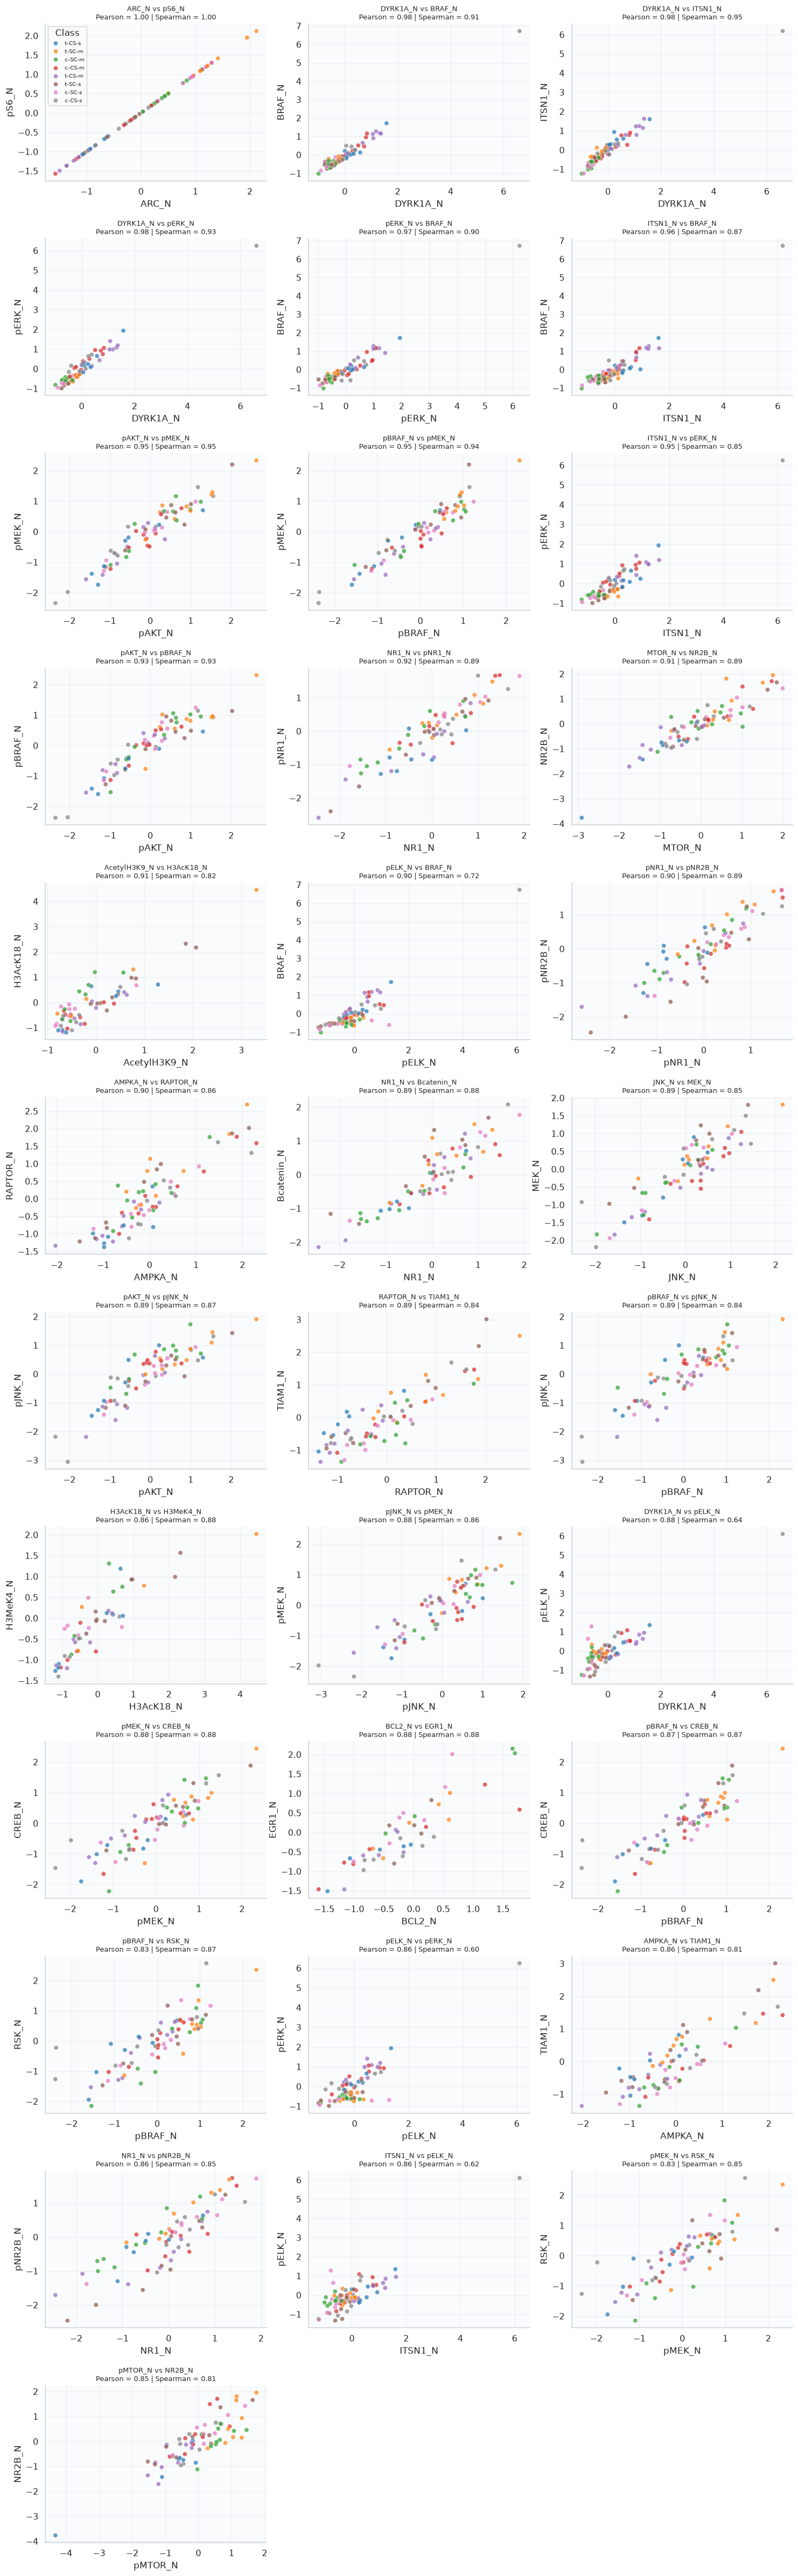

In [ ]:
umbral = 0.85

#Correlaciones de Pearson y Spearman
corr_p = data_mouse.corr(method='pearson')
corr_s = data_mouse.corr(method='spearman')

mask = np.triu(np.ones(corr_p.shape, dtype=bool), k=1)

pairs = pd.DataFrame({
    'Pearson': corr_p.where(mask).stack(),
    'Spearman': corr_s.where(mask).stack()
}).reset_index()

pairs.columns = ['proteina_A', 'proteina_B', 'Pearson', 'Spearman']

#Selecciono pares con correlación alta en al menos un método
pairs_altos = pairs[
    (pairs['Pearson'].abs() >= umbral) |
    (pairs['Spearman'].abs() >= umbral)
].copy()

pairs_altos['max_corr'] = pairs_altos[
    ['Pearson', 'Spearman']
].abs().max(axis=1)

pairs_altos = pairs_altos.sort_values(
    'max_corr', ascending=False
)

print(f"Pares con |r| >= {umbral}: {len(pairs_altos)}")
display(pairs_altos)

metadata = data.copy()

metadata['raton'] = (
    metadata['MouseID'].str.split('_').str[0]
)

class_map = (
    metadata.groupby('raton')['class']
    .first()
)

class_mouse = pd.Series(
    data_mouse.index.astype(str),
    index=data_mouse.index
).map(class_map)

# Grafico solo correlaciones altas
if len(pairs_altos) > 0:

    cols = 3
    rows = int(np.ceil(len(pairs_altos) / cols))

    fig, axes = plt.subplots(
        rows, cols,
        figsize=(5 * cols, 4 * rows),
        squeeze=False
    )

    axes = axes.ravel()

    for i, (_, row) in enumerate(pairs_altos.iterrows()):

        ax = axes[i]

        plot_data = pd.DataFrame({
            'x': data_mouse[row['proteina_A']],
            'y': data_mouse[row['proteina_B']],
            'class': class_mouse
        })

        sns.scatterplot(
            data=plot_data,
            x='x',
            y='y',
            hue='class',
            palette='tab10',
            alpha=0.7,
            s=35,
            ax=ax,
            legend=(i == 0)
        )

        ax.set_title(
            f"{row['proteina_A']} vs {row['proteina_B']}\n"
            f"Pearson = {row['Pearson']:.2f} | "
            f"Spearman = {row['Spearman']:.2f}",
            fontsize=9
        )

        ax.set_xlabel(row['proteina_A'])
        ax.set_ylabel(row['proteina_B'])

        if i == 0:
            ax.legend(
                title='Class',
                fontsize=7,
                loc='best'
            )
    for j in range(len(pairs_altos), len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()

### Correlaciones entre proteínas

Se observan numerosas correlaciones positivas elevadas entre distintas proteínas, tanto con Pearson como con Spearman, lo que sugiere posibles relaciones entre sus niveles de expresión y cierta redundancia en la información.

Estos resultados plantean la posibilidad de aplicar técnicas de **reducción de dimensionalidad, como PCA**, para identificar patrones comunes y representar los datos utilizando menos variables.

### Asociación entre proteínas y clases experimentales (η²)

Para explorar la relación entre las variables cuantitativas y categóricas, calculé **Eta cuadrado (η²)**, que representa la proporción de variabilidad de cada proteína asociada con las diferencias entre las clases experimentales.

Seleccioné las seis proteínas con mayor η² y se visualizaron sus distribuciones mediante boxplots, incluyendo las observaciones individuales de cada ratón.

Este análisis permite identificar proteínas con diferencias marcadas entre grupos y observar su variabilidad interna.

In [64]:
metadata = data.copy()
metadata['raton'] = metadata['MouseID'].str.split('_').str[0]

class_map = metadata.groupby('raton')['class'].first()

eda = data_mouse.copy()
eda.index = eda.index.astype(str)

eda['class'] = eda.index.map(class_map)

resultados = []

for proteina in num_cols:

    datos = eda[[proteina, 'class']].dropna()

    grupos = [
        g[proteina].values
        for _, g in datos.groupby('class')
    ]

    #ANOVA
    F, p = f_oneway(*grupos)

    #Eta cuadrado
    media_global = datos[proteina].mean()

    ss_total = (
        (datos[proteina] - media_global)**2
    ).sum()

    ss_entre = sum(
        len(g) * (g.mean() - media_global)**2
        for g in grupos
    )

    eta2 = ss_entre / ss_total if ss_total > 0 else np.nan

    resultados.append({
        'Proteina': proteina,
        'Eta2': eta2,
        'F': F,
        'p_value': p
    })

resultados = pd.DataFrame(resultados)

resultados = resultados.sort_values(
    'Eta2',
    ascending=False
)

display(resultados.head(20))

,Proteina,Eta2,F,p_value
32,SOD1_N,0.721227,23.653970,1.602616e-15
76,CaNA_N,0.668115,18.405372,3.540315e-13
53,ARC_N,0.649991,16.978900,1.817545e-12
70,pS6_N,0.649991,16.978900,1.817545e-12
34,P38_N,0.625861,15.294221,1.402412e-11
64,SNCA_N,0.618576,14.827491,2.528047e-11
65,Ubiquitin_N,0.606576,14.096309,6.502721e-11
30,APP_N,0.493866,8.921251,1.268592e-07
48,S6_N,0.463803,7.908459,6.940241e-07
45,pGSK3B_N,0.462054,7.853017,7.634924e-07


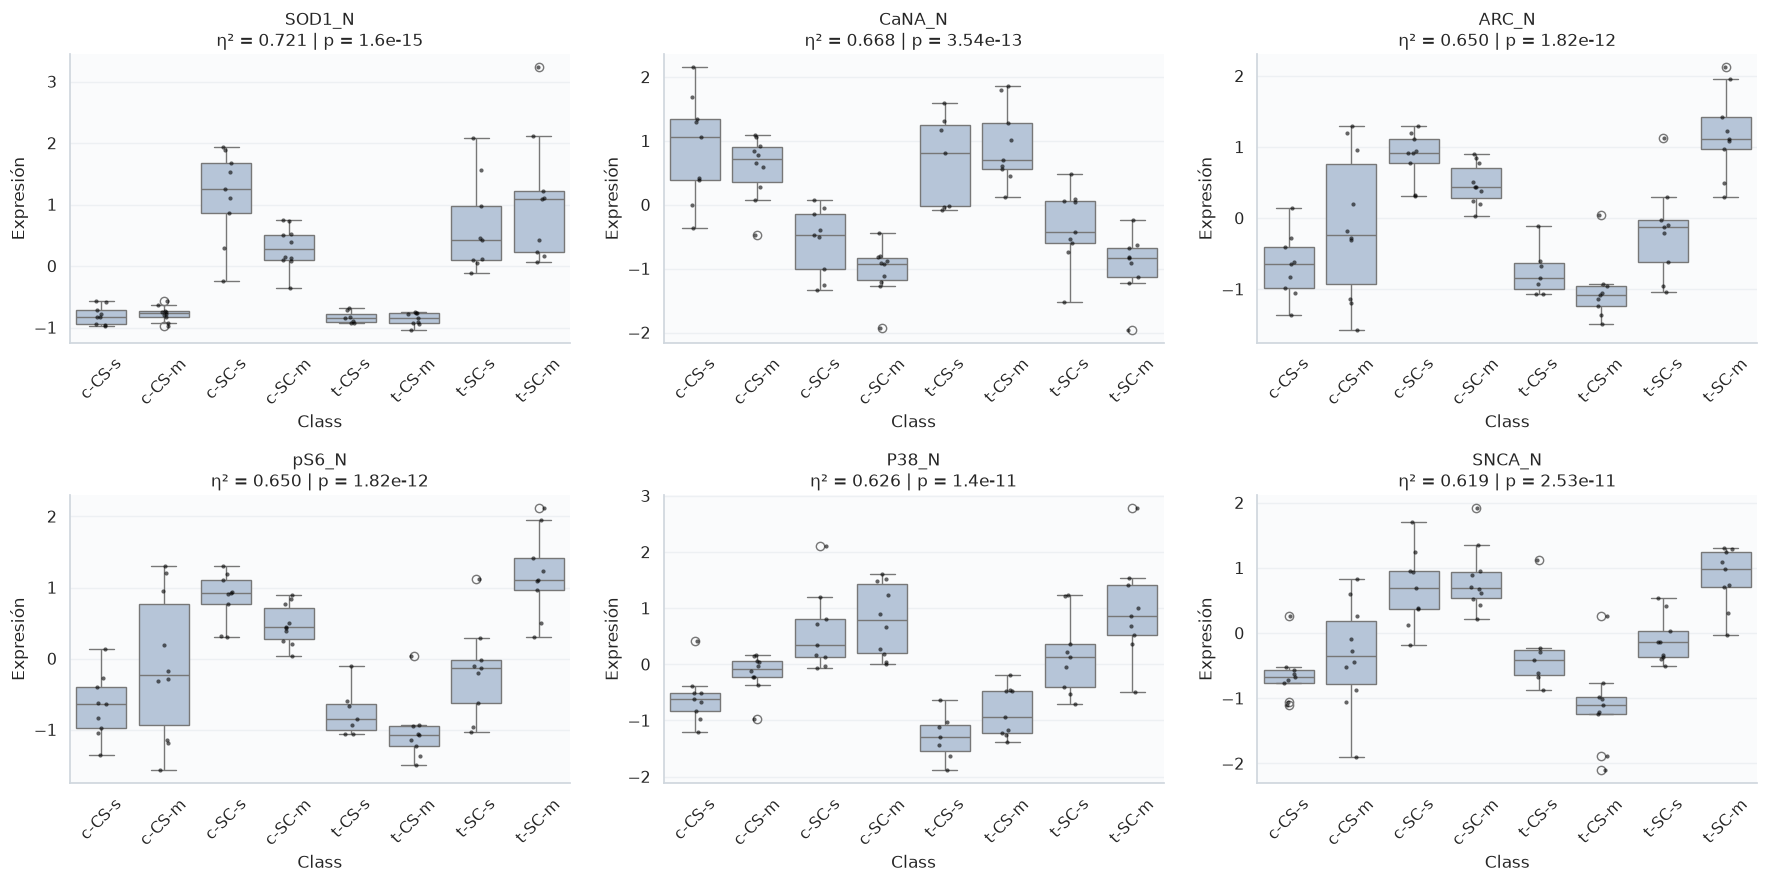

In [65]:
import matplotlib.pyplot as plt
import seaborn as sns

class_order = [
    'c-CS-s',
    'c-CS-m',
    'c-SC-s',
    'c-SC-m',
    't-CS-s',
    't-CS-m',
    't-SC-s',
    't-SC-m'
]

top = resultados.head(6)

fig, axes = plt.subplots(
    2, 3,
    figsize=(18, 9)
)

axes = axes.ravel()

for i, (_, row) in enumerate(top.iterrows()):

    proteina = row['Proteina']
    ax = axes[i]

    sns.boxplot(
        data=eda,
        x='class',
        y=proteina,
        order=class_order,
        color='lightsteelblue',
        ax=ax
    )

    sns.stripplot(
        data=eda,
        x='class',
        y=proteina,
        order=class_order,
        color='black',
        alpha=0.6,
        size=3,
        jitter=True,
        ax=ax
    )

    ax.set_title(
        f"{proteina}\n"
        f"η² = {row['Eta2']:.3f} | "
        f"p = {row['p_value']:.3g}"
    )

    ax.tick_params(axis='x', rotation=45)
    ax.set_xlabel('Class')
    ax.set_ylabel('Expresión')

plt.tight_layout()
plt.show()

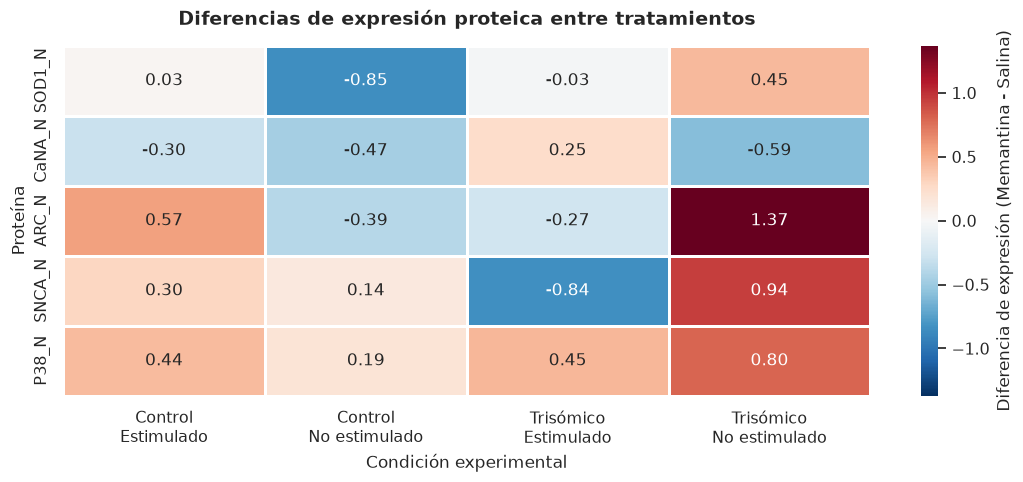

In [71]:
proteinas = [
    'SOD1_N',
    'CaNA_N',
    'ARC_N',
    'SNCA_N',
    'P38_N'
]

#Media de expresión para cada condición experimental
medias = (
    eda.groupby(
        ['Genotipo', 'Aprendizaje', 'Tratamiento']
    )[proteinas]
    .mean()
    .unstack('Tratamiento')
)

# Diferencia entre tratamientos
# Valores positivos: mayor expresión con memantina
# Valores negativos: mayor expresión con salina
diferencias = (
    medias.xs('Memantina', level='Tratamiento', axis=1)
    - medias.xs('Salina', level='Tratamiento', axis=1)
)

heatmap_data = diferencias.T

heatmap_data.columns = [
    f"{genotipo}\n{aprendizaje}"
    for genotipo, aprendizaje in heatmap_data.columns
]

fig, ax = plt.subplots(figsize=(11, 5))

limite = np.nanmax(np.abs(heatmap_data.to_numpy()))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-limite,
    vmax=limite,
    linewidths=0.8,
    linecolor="white",
    cbar_kws={
        "label": "Diferencia de expresión (Memantina - Salina)"
    },
    ax=ax
)

ax.set_title(
    "Diferencias de expresión proteica entre tratamientos",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Condición experimental")
ax.set_ylabel("Proteína")

plt.tight_layout()
plt.show()


### Diferencias de expresión entre tratamientos

El análisis exploratorio muestra diferencias en la expresión proteica entre memantina y salina, cuya magnitud y dirección varían según el genotipo y la condición de estimulación.

Destacan **ARC_N y SNCA_N**, que presentan diferencias positivas en ratones trisómicos no estimulados, mientras que **P38_N** muestra diferencias positivas en todas las condiciones.

Estos resultados sugieren posibles interacciones entre tratamiento, genotipo y estimulación, aunque se requieren análisis estadísticos adicionales para evaluar su significancia.

Por ejemplo, ARC es especialmente interesante para aprendizaje y memoria siendo una proteína muy estudiada en neurociencia.

Su expresión puede aumentar rápidamente en respuesta a la actividad neuronal y participa en procesos como la plasticidad sináptica, la regulación de receptores AMPA y la consolidación de recuerdos.

Es particularmente interesante porque los mecanismos de aprendizaje dependen de la capacidad de las sinapsis para modificar su funcionamiento.

